# Title : Data Wrangling on Real Estate Market

In [1]:
# Import libraries for data cleaning, numerical calculations, and plotting
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
import warnings

In [2]:
# Supressing update warnings
warnings.filterwarnings('ignore')

In [3]:
# Load the Bengaluru house price dataset
df1 = pd.read_csv("Bengaluru_House_Data.csv") 

In [4]:
# Display the first five house records
df1.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [5]:
# Check the number of rows and columns in the dataset
df1.shape 

(13320, 9)

In [6]:
# Display the dataset column names
df1.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='str')

In [7]:
# Display the area type column
df1['area_type']

0        Super built-up  Area
1                  Plot  Area
2              Built-up  Area
3        Super built-up  Area
4        Super built-up  Area
                 ...         
13315          Built-up  Area
13316    Super built-up  Area
13317          Built-up  Area
13318    Super built-up  Area
13319    Super built-up  Area
Name: area_type, Length: 13320, dtype: str

In [8]:
# Find the unique area types
df1['area_type'].unique()

<ArrowStringArray>
['Super built-up  Area', 'Plot  Area', 'Built-up  Area', 'Carpet  Area']
Length: 4, dtype: str

In [9]:
# Count records for each area type
df1['area_type'].value_counts()

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

In [10]:
# Remove columns that are not required for price prediction
df2 = df1.drop(['area_type','society','balcony','availability'],axis='columns') 

In [11]:
# Check the shape of the reduced dataset
df2.shape

(13320, 5)

In [12]:
# Count missing values in each column
df2.isnull().sum()

location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

In [13]:
# Check the dataset dimensions before removing missing values
df2.shape 

(13320, 5)

In [14]:
# Remove rows containing missing values and verify the result
df3 = df2.dropna() 
df3.isnull().sum()

location      0
size          0
total_sqft    0
bath          0
price         0
dtype: int64

In [15]:
# Check the dimensions after removing missing values
df3.shape 

(13246, 5)

In [16]:
# Display the unique values in the size column
df3['size'].unique()

<ArrowStringArray>
[     '2 BHK',  '4 Bedroom',      '3 BHK',      '4 BHK',  '6 Bedroom',
  '3 Bedroom',      '1 BHK',       '1 RK',  '1 Bedroom',  '8 Bedroom',
  '2 Bedroom',  '7 Bedroom',      '5 BHK',      '7 BHK',      '6 BHK',
  '5 Bedroom',     '11 BHK',      '9 BHK',  '9 Bedroom',     '27 BHK',
 '10 Bedroom', '11 Bedroom',     '10 BHK',     '19 BHK',     '16 BHK',
 '43 Bedroom',     '14 BHK',      '8 BHK', '12 Bedroom',     '13 BHK',
 '18 Bedroom']
Length: 31, dtype: str

In [17]:
# Extract the number of bedrooms from the size column
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))

In [18]:
# Display the dataset with the extracted bedroom count
df3.head()

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,4
2,Uttarahalli,3 BHK,1440,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,3
4,Kothanur,2 BHK,1200,2.0,51.00,2


In [19]:
# Display the unique bedroom counts
df3.bhk.unique()

array([ 2,  4,  3,  6,  1,  8,  7,  5, 11,  9, 27, 10, 19, 16, 43, 14, 12,
       13, 18])

In [20]:
# Find records with more than 20 bedrooms
df3[df3.bhk>20]

,location,size,total_sqft,bath,price,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [21]:
# Display the unique values in the total square feet column
df3.total_sqft.unique()

<ArrowStringArray>
[       '1056',        '2600',        '1440',        '1521',        '1200',
        '1170',        '2732',        '3300',        '1310',        '1020',
 ...
        '1379',        '3124',        '9200',         '613',         '250',
        '2395',        '2758', '1133 - 1384',         '774',        '4689']
Length: 2067, dtype: str

In [22]:
# Define a function to check whether a value can be converted to a float
def is_float(x):
    try:
        float(x) 
        return True
    except(ValueError, TypeError):
        return False 

In [23]:
# Find total square feet values that are not directly numeric
df3[~df3['total_sqft'].apply(is_float)].head(10)

,location,size,total_sqft,bath,price,bhk
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,4
122,Hebbal,4 BHK,3067 - 8156,4.0,477.000,4
137,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,2
165,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,2
188,KR Puram,2 BHK,1015 - 1540,2.0,56.800,2
410,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1
549,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,2
648,Arekere,9 Bedroom,4125Perch,9.0,265.000,9
661,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,2
672,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,4


In [24]:
# Define a function to convert square feet ranges and numeric values into numbers
def convert_sqft_to_num(x): 
    tokens = x.split('-')
    if len(tokens) == 2:
        try:
            return (float(tokens[0])+float(tokens[1]))/2
        except ValueError:
            return None
    try:
        return float(x) 
    except ValueError:
        return None 
    
result = convert_sqft_to_num('2100 - 2850')
print(result)

2475.0


In [25]:
# Convert total square feet values into numeric format
convert_sqft_to_num('34.46Sq. Meter') 
df4 = df3.copy()
df4.total_sqft = df4.total_sqft.apply(convert_sqft_to_num) 
df4

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2
...,...,...,...,...,...,...
13315,Whitefield,5 Bedroom,3453.0,4.0,231.00,5
13316,Richards Town,4 BHK,3600.0,5.0,400.00,4
13317,Raja Rajeshwari Nagar,2 BHK,1141.0,2.0,60.00,2
13318,Padmanabhanagar,4 BHK,4689.0,4.0,488.00,4


In [26]:
# Remove rows where total square feet could not be converted
df4 = df4[df4.total_sqft.notnull()] 
df4

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2
...,...,...,...,...,...,...
13315,Whitefield,5 Bedroom,3453.0,4.0,231.00,5
13316,Richards Town,4 BHK,3600.0,5.0,400.00,4
13317,Raja Rajeshwari Nagar,2 BHK,1141.0,2.0,60.00,2
13318,Padmanabhanagar,4 BHK,4689.0,4.0,488.00,4


In [27]:
# Inspect the house record at index 30
df4.loc[30]

location      Yelahanka
size              4 BHK
total_sqft       2475.0
bath                4.0
price             186.0
bhk                   4
Name: 30, dtype: object

In [28]:
# Calculate the price per square foot for each property
df5 = df4.copy()
df5['price_per_sqft'] = df5['price']*100000/df5['total_sqft'] 
df5.head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [29]:
# Generate summary statistics for price per square foot
df5_stats = df5['price_per_sqft'].describe() 
df5_stats

count    1.320000e+04
mean     7.920759e+03
std      1.067272e+05
min      2.678298e+02
25%      4.267701e+03
50%      5.438331e+03
75%      7.317073e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64

In [30]:
# Export the processed house dataset to a CSV file
df5.to_csv("bhp.csv",index=False)

In [31]:
# Remove extra spaces from location names and count properties by location
df5.location = df5.location.apply(lambda x: x.strip()) 
location_stats = df5['location'].value_counts(ascending=False) 
location_stats

location
Whitefield                                         533
Sarjapur  Road                                     392
Electronic City                                    304
Kanakpura Road                                     264
Thanisandra                                        235
                                                  ... 
Pattegarhpalya                                       1
Tilak Nagar                                          1
12th cross srinivas nagar banshankari 3rd stage      1
Havanur extension                                    1
Abshot Layout                                        1
Name: count, Length: 1287, dtype: int64

In [32]:
# Count locations that have more than 10 records
len(location_stats[location_stats>10])

240

In [33]:
# Count the total number of locations
len(location_stats) 

1287

In [34]:
# Count locations that have 10 or fewer records
len(location_stats[location_stats<=10]) 

1047

In [35]:
# Identify locations with 10 or fewer records
location_stats_less_than_10 = location_stats[location_stats<=10] 
location_stats_less_than_10

location
Ganga Nagar                                        10
Dairy Circle                                       10
Sadashiva Nagar                                    10
Naganathapura                                      10
Nagappa Reddy Layout                               10
                                                   ..
Pattegarhpalya                                      1
Tilak Nagar                                         1
12th cross srinivas nagar banshankari 3rd stage     1
Havanur extension                                   1
Abshot Layout                                       1
Name: count, Length: 1047, dtype: int64

In [36]:
# Count the number of unique locations
len(df5.location.unique())

1287

In [37]:
# Group low-frequency locations under the category other
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x) 
len(df5.location.unique())

241

In [38]:
# Display the first ten records after grouping locations
df5.head(10)

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248
6,Old Airport Road,4 BHK,2732.0,4.0,204.00,4,7467.057101
7,Rajaji Nagar,4 BHK,3300.0,4.0,600.00,4,18181.818182
8,Marathahalli,3 BHK,1310.0,3.0,63.25,3,4828.244275
9,other,6 Bedroom,1020.0,6.0,370.00,6,36274.509804


In [39]:
# Find properties with less than 300 square feet per bedroom
df5[df5.total_sqft/df5.bhk<300].head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
45,HSR Layout,8 Bedroom,600.0,9.0,200.0,8,33333.333333
58,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,6,10660.980810
68,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,8,6296.296296
70,other,3 Bedroom,500.0,3.0,100.0,3,20000.000000


In [40]:
# Check the dataset dimensions before removing small-area properties
df5.shape 

(13200, 7)

In [41]:
# Remove properties with less than 300 square feet per bedroom
df6 = df5[~(df5.total_sqft/df5.bhk<300)] 
df6.shape

(12456, 7)

In [42]:
# Display the column names after filtering
df6.columns

Index(['location', 'size', 'total_sqft', 'bath', 'price', 'bhk',
       'price_per_sqft'],
      dtype='str')

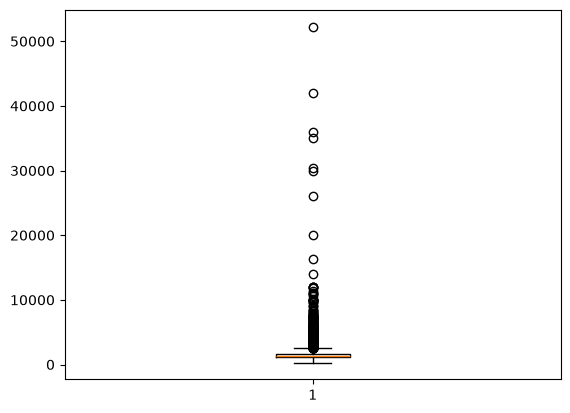

In [43]:
# Visualize total square feet values using a box plot
plt.boxplot(df6['total_sqft']) 
plt.show()

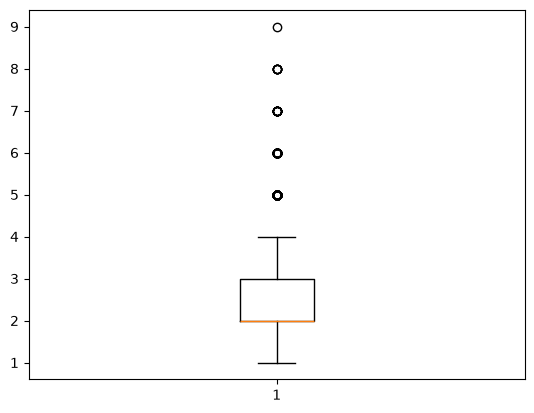

In [44]:
# Detect and remove total square feet outliers using the IQR method
Q1 = np.percentile(df6['total_sqft'], 25.) # 25th percentile of the data of the given feature 
Q3 = np.percentile(df6['total_sqft'], 75.) # 75th percentile of the data of the given feature 
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR) 
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['total_sqft'] > ul].index.tolist() 
lower_outliers = df6[df6['total_sqft'] < ll].index.tolist() 
bad_indices = list(set(upper_outliers + lower_outliers)) 
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bath']) 
plt.show()

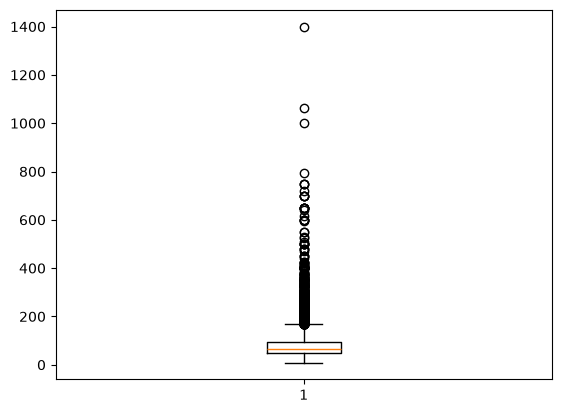

In [45]:
# Detect and remove bathroom-count outliers using the IQR method
Q1 = np.percentile(df6['bath'], 25.) # 25th percentile of the data of the given feature 
Q3 = np.percentile(df6['bath'], 75.) # 75th percentile of the data of the given feature 
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR) 
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bath'] > ul].index.tolist() 
lower_outliers = df6[df6['bath'] < ll].index.tolist() 
bad_indices = list(set(upper_outliers + lower_outliers)) 
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')
plt.boxplot(df6['price']) 
plt.show()

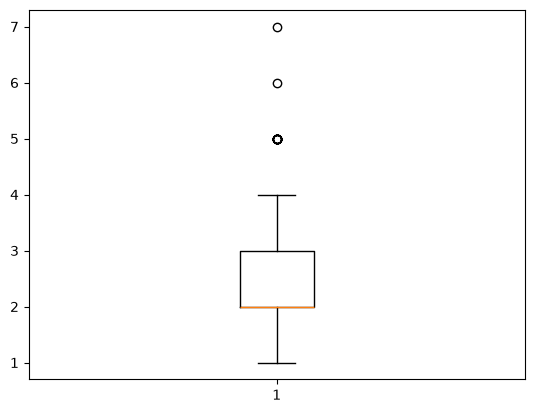

In [46]:
# Detect and remove property-price outliers using the IQR method
Q1 = np.percentile(df6['price'], 25.) # 25th percentile of the data of the given feature 
Q3 = np.percentile(df6['price'], 75.) # 75th percentile of the data of the given feature 
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR) 
ul = Q3 + (1.5*IQR)
 
upper_outliers = df6[df6['price'] > ul].index.tolist() 
lower_outliers = df6[df6['price'] < ll].index.tolist() 
bad_indices = list(set(upper_outliers + lower_outliers)) 
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['bhk']) 
plt.show()

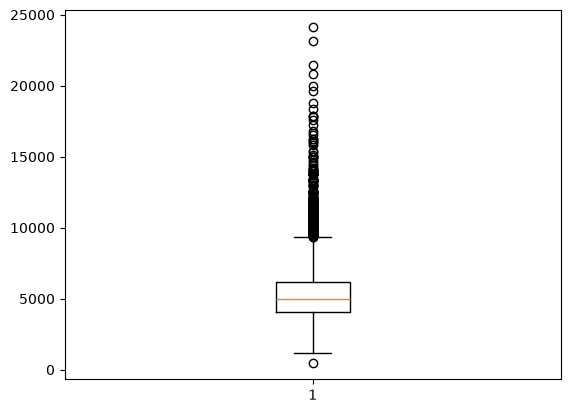

In [47]:
# Detect and remove bedroom-count outliers using the IQR method
Q1 = np.percentile(df6['bhk'], 25.) # 25th percentile of the data of the given feature 
Q3 = np.percentile(df6['bhk'], 75.) # 75th percentile of the data of the given feature 
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR) 
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['bhk'] > ul].index.tolist() 
lower_outliers = df6[df6['bhk'] < ll].index.tolist() 
bad_indices = list(set(upper_outliers + lower_outliers)) 
drop = True
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft']) 
plt.show()

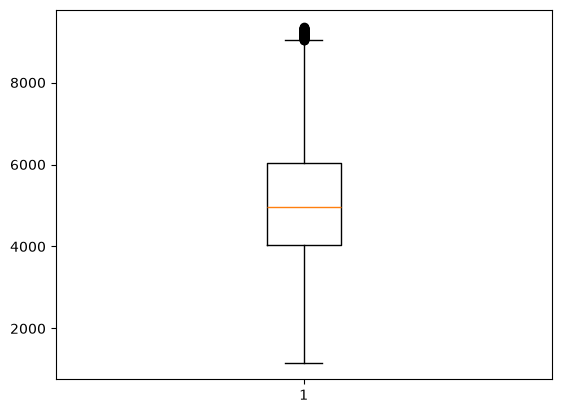

In [48]:
# Detect and remove price-per-square-foot outliers using the IQR method
Q1 = np.percentile(df6['price_per_sqft'], 25.) # 25th percentile of the data of the given feature 
Q3 = np.percentile(df6['price_per_sqft'], 75.) # 75th percentile of the data of the given feature 
IQR = Q3-Q1 #Interquartile Range
ll = Q1 - (1.5*IQR) 
ul = Q3 + (1.5*IQR)
upper_outliers = df6[df6['price_per_sqft'] > ul].index.tolist() 
lower_outliers = df6[df6['price_per_sqft'] < ll].index.tolist() 
bad_indices = list(set(upper_outliers + lower_outliers))
drop = True 
if drop:
    df6.drop(bad_indices, inplace = True, errors = 'ignore')

plt.boxplot(df6['price_per_sqft']) 
plt.show()

In [49]:
# Check the dataset dimensions after outlier removal
df6.shape

(10090, 7)

In [50]:
# Separate input features from the house price target
X = df6.drop(['price'],axis='columns') 
X.head(3)

,location,size,total_sqft,bath,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,2,3699.810606
2,Uttarahalli,3 BHK,1440.0,2.0,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,3,6245.890861


In [51]:
# Check the shape of the input feature dataset
X.shape 

(10090, 6)

In [52]:
# Select house price as the target variable
y = df6.price 
y.head(3)

0    39.07
2    62.00
3    95.00
Name: price, dtype: float64

In [53]:
# Check the number of target values
len(y)

10090

In [54]:
# Split the features and target into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=10)

X_train.shape 

(8072, 6)

In [55]:
# Check the shape of the training feature set
y_train.shape 

(8072,)

In [56]:
# Check the shape of the training target set
X_test.shape 

(2018, 6)

In [57]:
# Check the shape of the testing feature set
y_test.shape 

(2018,)